# HeartGuard v2 — Quy trình Retrain & Đánh giá Mô hình
**Mục tiêu:** Khắc phục lỗi lệch thang đo, bỏ data leakage, tối ưu ngưỡng theo **Recall (tỉ lệ bắt bệnh)** và đóng gói thành một `Pipeline` duy nhất.

đo pipeline

In [2]:
import sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
# Trỏ về thư mục gốc repo (nếu notebook đang nằm trong notebook/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT / "api"))
from app.ml import build_feature_dict, run_inference
df_raw = pd.read_csv(ROOT / "data/raw_data/heart_disease_uci.csv")
df_v1 = df_raw.dropna(subset=["age", "trestbps", "chol", "thalch", "oldpeak"])
df_v1 = df_v1[(df_v1.chol > 0) & (df_v1.trestbps > 0)].copy()
model_v1 = joblib.load(ROOT / "models/random_forest_model.pkl")
scaler_v1 = joblib.load(ROOT / "models/heart_scaler.pkl")
names_v1 = joblib.load(ROOT / "models/feature_names.pkl")

* Giả lập đúng dữ liệu từ Form Web gửi lên API

In [3]:
def to_v1_payload(r):
    return dict(
        age=r.age, sex=int(r.sex == "Male"), trestbps=r.trestbps, chol=r.chol,
        fbs=int(r.fbs is True), thalch=r.thalch, exang=int(r.exang is True), oldpeak=r.oldpeak,
        cp_typical_angina=int(r.cp == "typical angina"),
        cp_atypical_angina=int(r.cp == "atypical angina"),
        cp_non_anginal=int(r.cp == "non-anginal"),
        restecg_normal=int(r.restecg == "normal"),
        restecg_st_t_abnormality=int(r.restecg == "st-t abnormality"),
        slope_flat=int(r.slope == "flat"),
        slope_upsloping=int(r.slope == "upsloping"),
        ca_missing=0, thal_missing=0,
        dataset_Hungary=0, dataset_Switzerland=0, dataset_VA_Long_Beach=0,
        age_under_40=int(r.age < 40), bp_age_ratio=r.trestbps / r.age,
    )

y_true_v1, y_pred_v1, p_disease_v1 = [], [], []
for r in df_v1.itertuples():
    feats = build_feature_dict(to_v1_payload(r), None, names_v1)
    pred, _ = run_inference(model_v1, scaler_v1, feats, names_v1)
    X_row = pd.DataFrame([feats])[names_v1]
    p1 = float(model_v1.predict_proba(scaler_v1.transform(X_row))[0][1])
    y_true_v1.append(int(r.num > 0))
    y_pred_v1.append(pred)
    p_disease_v1.append(p1)

y_true_v1, y_pred_v1, p_disease_v1 = map(np.array, (y_true_v1, y_pred_v1, p_disease_v1))
print("Đã chạy xong dự đoán cho toàn bộ mẫu.")

e:\heart predict\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
e:\heart predict\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
e:\heart predict\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
e:\heart predict\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
e:\heart predict\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
e:\he

Đã chạy xong dự đoán cho toàn bộ mẫu.


e:\heart predict\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
e:\heart predict\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
e:\heart predict\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
e:\heart predict\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
e:\heart predict\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
e:\he

* In chỉ số đo lường & Vẽ biểu đồ Baseline v1, tính recall  trong 100 ng bệnh thì model bắt được bao nhiêu

Recall (Tỉ lệ bắt bệnh):  0.239  -> Bỏ sót 242/318 ca có bệnh!
Specificity (Đúng khỏe):  0.271
Accuracy:                 0.256
ROC-AUC:                  0.192


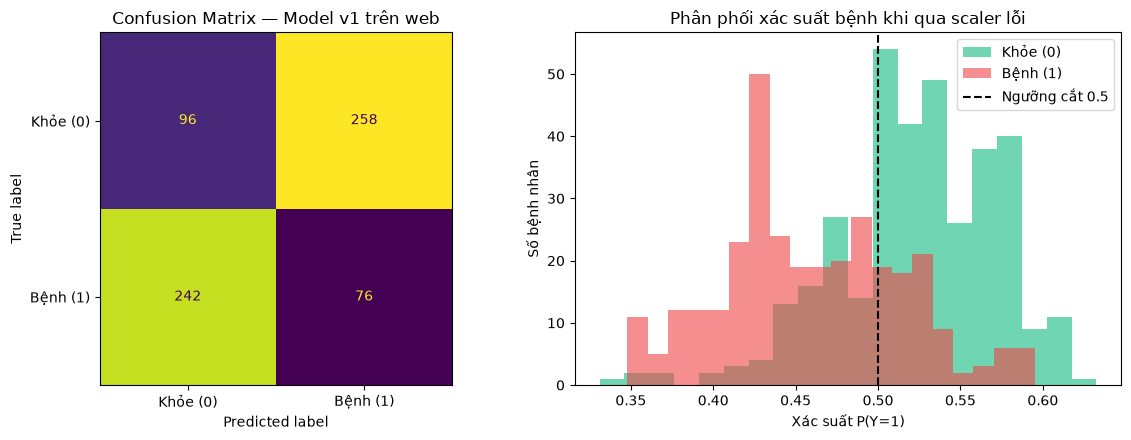

In [4]:
tn, fp, fn, tp = confusion_matrix(y_true_v1, y_pred_v1).ravel()
print(f"Recall (Tỉ lệ bắt bệnh):  {tp/(tp+fn):.3f}  -> Bỏ sót {fn}/{tp+fn} ca có bệnh!")
print(f"Specificity (Đúng khỏe):  {tn/(tn+fp):.3f}")
print(f"Accuracy:                 {(tp+tn)/len(y_true_v1):.3f}")
print(f"ROC-AUC:                  {roc_auc_score(y_true_v1, p_disease_v1):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_true_v1, y_pred_v1), display_labels=["Khỏe (0)", "Bệnh (1)"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix — Model v1 trên web")

axes[1].hist(p_disease_v1[y_true_v1 == 0], bins=20, alpha=0.6, label="Khỏe (0)", color="#10b981")
axes[1].hist(p_disease_v1[y_true_v1 == 1], bins=20, alpha=0.6, label="Bệnh (1)", color="#ef4444")
axes[1].axvline(0.5, color="black", linestyle="--", label="Ngưỡng cắt 0.5")
axes[1].set_title("Phân phối xác suất bệnh khi qua scaler lỗi")
axes[1].set_xlabel("Xác suất P(Y=1)")
axes[1].set_ylabel("Số bệnh nhân")
axes[1].legend()
plt.tight_layout()
plt.show()

* sau khi xem kết quả với plot thì mô hình kém và cần phải retrain, tinh chỉnh scaler lại

#### Kiểm tra dữ liệu thiếu & giá trị 0 bất thường theo từng bệnh viện

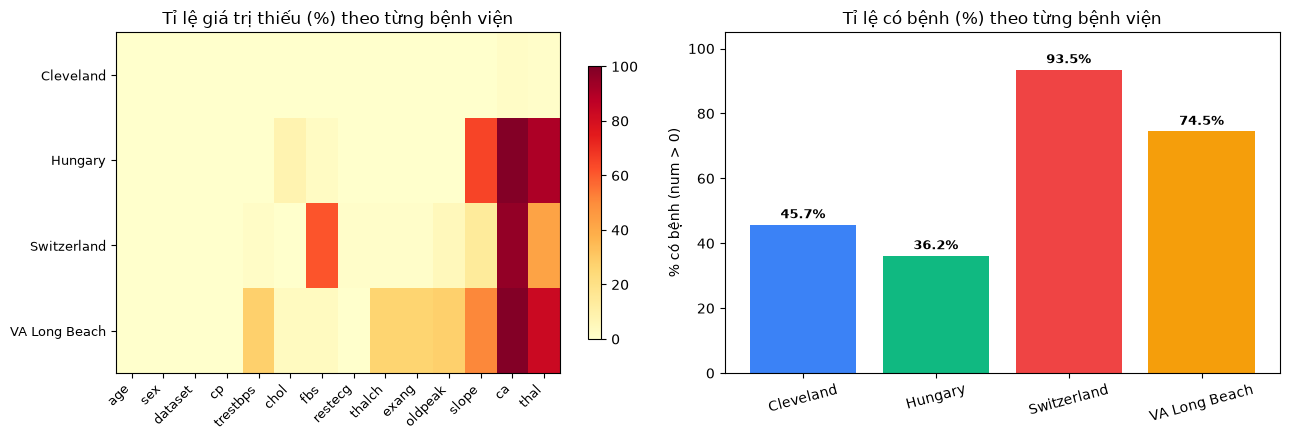

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Tỉ lệ missing theo bệnh viện
missing_by_src = df_raw.drop(columns=["id", "num"]).isna().groupby(df_raw["dataset"]).mean() * 100
im = axes[0].imshow(missing_by_src.values, cmap="YlOrRd", aspect="auto", vmin=0, vmax=100)
axes[0].set_xticks(range(len(missing_by_src.columns)))
axes[0].set_xticklabels(missing_by_src.columns, rotation=45, ha="right", fontsize=9)
axes[0].set_yticks(range(len(missing_by_src.index)))
axes[0].set_yticklabels(missing_by_src.index, fontsize=9)
axes[0].set_title("Tỉ lệ giá trị thiếu (%) theo từng bệnh viện")
plt.colorbar(im, ax=axes[0], shrink=0.8)

# 2. Tỉ lệ mắc bệnh theo bệnh viện
disease_rate = df_raw.groupby("dataset")["num"].apply(lambda s: (s > 0).mean() * 100)
bars = axes[1].bar(disease_rate.index, disease_rate.values, color=["#3b82f6", "#10b981", "#ef4444", "#f59e0b"])
axes[1].set_title("Tỉ lệ có bệnh (%) theo từng bệnh viện")
axes[1].set_ylabel("% có bệnh (num > 0)")
axes[1].set_ylim(0, 105)
axes[1].tick_params(axis="x", rotation=15)
for bar, val in zip(bars, disease_rate.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 2, f"{val:.1f}%", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

* sau khi xem xet ta thấy tỉ lệ thiếu sắp xếp theo giảm dần từ VA Long Beach - Hungary - Switzerland - Cleveland, còn tỉ lệ % bệnh theo từng bệnh viện thì thấy rõ trong biểu đồ và csv k nói lại

#### Kiểm tra các giá trị 0 bất thường ở Cholesterol & Huyết áp

Số ca chol == 0 theo nguồn:
dataset
Switzerland      123
VA Long Beach     49
Name: count, dtype: int64

Số ca trestbps == 0: 1


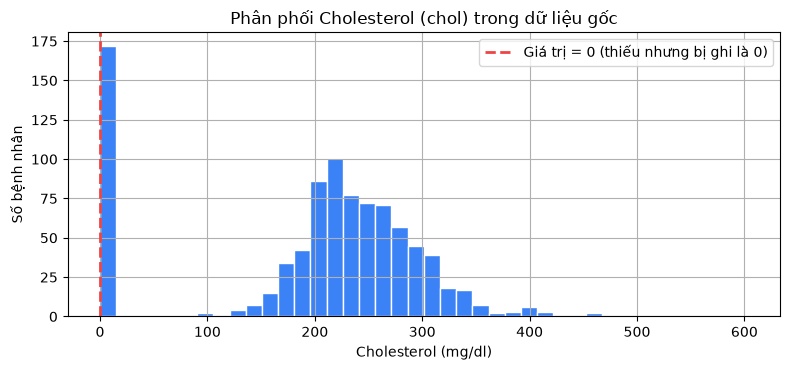

In [6]:
print("Số ca chol == 0 theo nguồn:")
print(df_raw[df_raw["chol"] == 0]["dataset"].value_counts())
print("\nSố ca trestbps == 0:", (df_raw["trestbps"] == 0).sum())

fig, ax = plt.subplots(figsize=(8, 3.8))
df_raw["chol"].dropna().hist(bins=40, ax=ax, color="#3b82f6", edgecolor="white")
ax.axvline(0, color="#ef4444", linestyle="--", linewidth=2, label="Giá trị = 0 (thiếu nhưng bị ghi là 0)")
ax.set_title("Phân phối Cholesterol (chol) trong dữ liệu gốc")
ax.set_xlabel("Cholesterol (mg/dl)")
ax.set_ylabel("Số bệnh nhân")
ax.legend()
plt.tight_layout()
plt.show()

* Toàn bộ 123 ca của Switzerland (gần 100% bệnh viện này) và 49 ca của VA Long Beach đều có chol == 0, cộng thêm 1 ca trestbps == 0.
* Trên biểu đồ, cột chol = 0 dựng đứng gần 175 bệnh nhân tách biệt hoàn toàn khỏi phân phối thật (100–500 mg/dl). Nếu không biến thành NaN, giá trị trung bình của chol bị kéo tụt thê thảm.

#### Kiểm tra trùng lặp, min/max, ngoại lai (Boxplot) của các biến số

1. Số dòng trùng (nếu bỏ id): 2
2. Số dòng thiếu nhãn (num): 0

3. Thống kê min/max/median (khi chưa xử lý 0):


,count,mean,std,min,50%,max
age,920.0,53.510870,9.424685,28.0,54.0,77.0
trestbps,861.0,132.132404,19.066070,0.0,130.0,200.0
chol,890.0,199.130337,110.780810,0.0,223.0,603.0
thalch,865.0,137.545665,25.926276,60.0,140.0,202.0
oldpeak,858.0,0.878788,1.091226,-2.6,0.5,6.2


C:\Users\khanh\AppData\Local\Temp\ipykernel_26060\2469669938.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df_tmp[col].dropna(), vert=True)
C:\Users\khanh\AppData\Local\Temp\ipykernel_26060\2469669938.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df_tmp[col].dropna(), vert=True)
C:\Users\khanh\AppData\Local\Temp\ipykernel_26060\2469669938.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df_tmp[col].dropna(), vert=True)
C:\Users\khanh\AppData\Local\Temp\ipykernel_26060\2469669938.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation

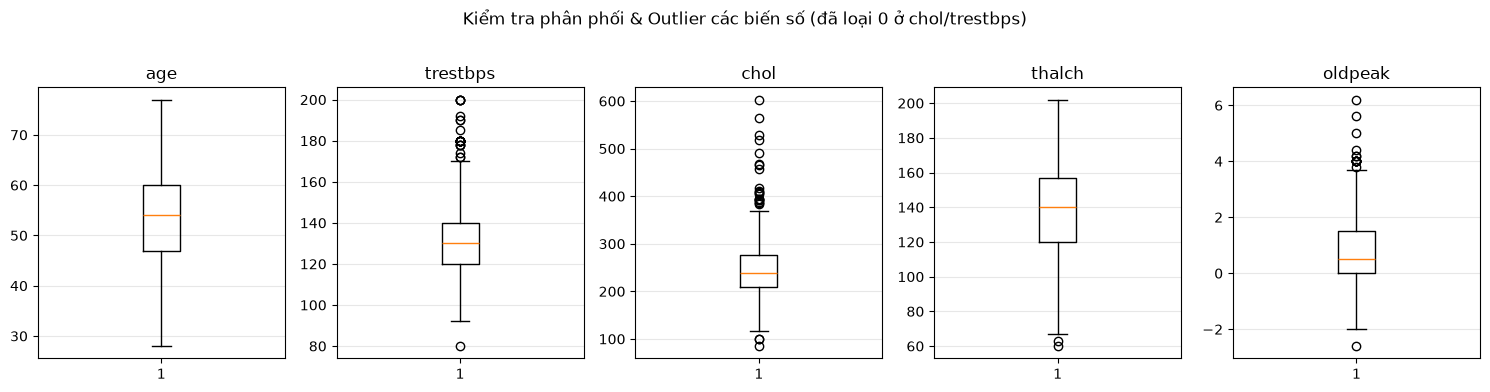

In [7]:
print("1. Số dòng trùng (nếu bỏ id):", df_raw.duplicated(subset=[c for c in df_raw.columns if c != "id"]).sum())
print("2. Số dòng thiếu nhãn (num):", df_raw["num"].isna().sum())

num_check = ["age", "trestbps", "chol", "thalch", "oldpeak"]
print("\n3. Thống kê min/max/median (khi chưa xử lý 0):")
display(df_raw[num_check].describe().T[["count", "mean", "std", "min", "50%", "max"]])

# Vẽ Boxplot sau khi tạm coi 0 ở chol/trestbps là NaN để xem outlier thật sự
df_tmp = df_raw[num_check].copy()
df_tmp.loc[df_tmp["chol"] == 0, "chol"] = np.nan
df_tmp.loc[df_tmp["trestbps"] == 0, "trestbps"] = np.nan

fig, axes = plt.subplots(1, 5, figsize=(15, 3.8))
for ax, col in zip(axes, num_check):
    ax.boxplot(df_tmp[col].dropna(), vert=True)
    ax.set_title(col)
    ax.grid(axis="y", alpha=0.3)
plt.suptitle("Kiểm tra phân phối & Outlier các biến số (đã loại 0 ở chol/trestbps)", y=1.02)
plt.tight_layout()
plt.show()

* Kiểm tra toàn bộ biến phân loại & Tỉ lệ bệnh theo từng nhóm

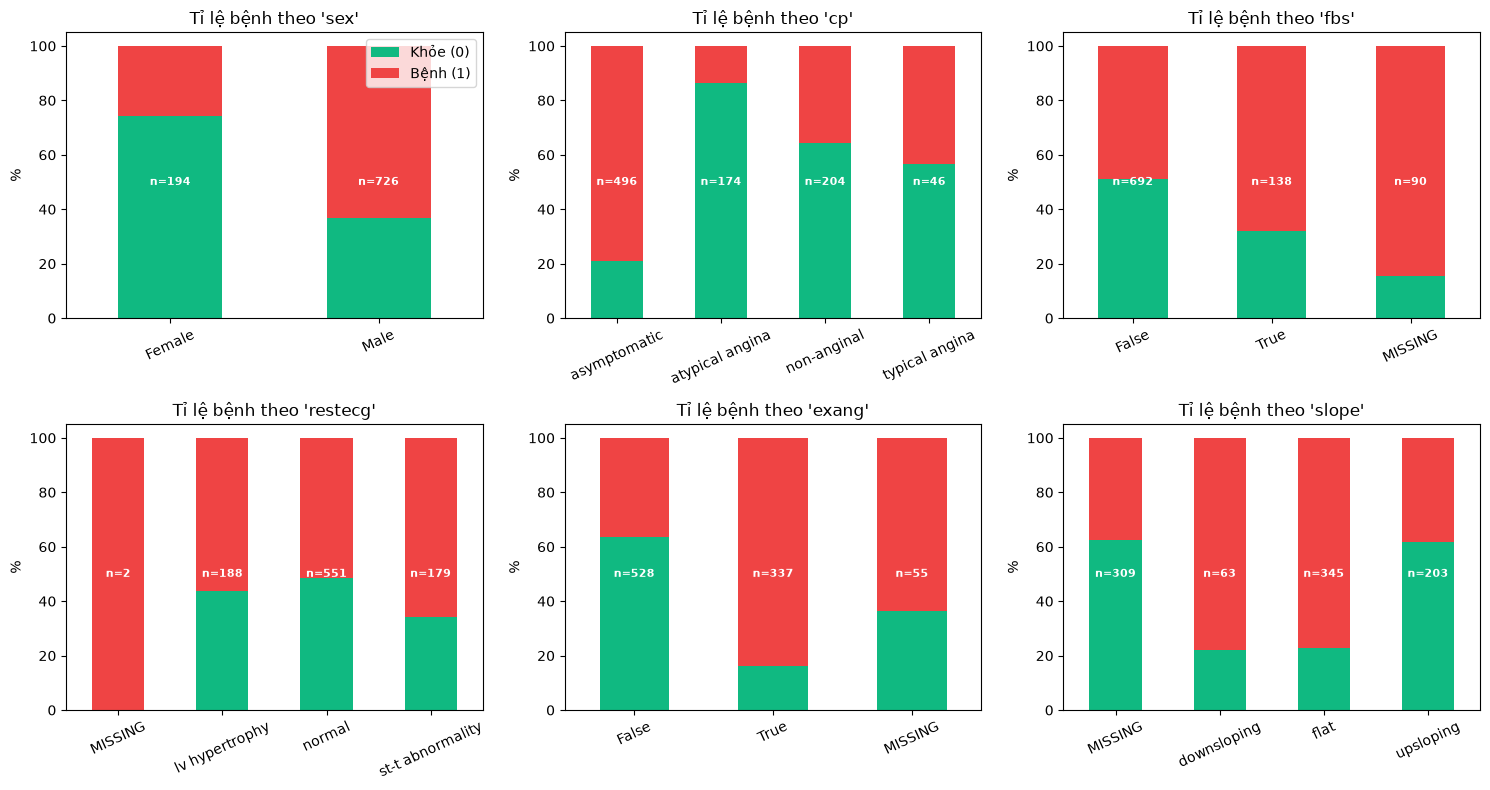

In [8]:
cat_check = ["sex", "cp", "fbs", "restecg", "exang", "slope"]
df_tmp_cat = df_raw.copy()
df_tmp_cat["target"] = (df_tmp_cat["num"] > 0).astype(int)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cat_check):
    ct = pd.crosstab(df_tmp_cat[col].fillna("MISSING"), df_tmp_cat["target"], normalize="index") * 100
    ct.plot(kind="bar", stacked=True, ax=ax, color=["#10b981", "#ef4444"], legend=False)
    ax.set_title(f"Tỉ lệ bệnh theo '{col}'")
    ax.set_ylabel("%")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
    for i, idx in enumerate(ct.index):
        n_grp = (df_tmp_cat[col].fillna("MISSING") == idx).sum()
        ax.text(i, 50, f"n={n_grp}", ha="center", va="center", color="white", fontweight="bold", fontsize=8)

axes[0, 0].legend(["Khỏe (0)", "Bệnh (1)"], loc="upper right")
plt.tight_layout()
plt.show()

# Làm sạch dựa trên những gì đã kiểm tra

| Quan sát từ biểu đồ | Quyết định xử lý | Lý do y khoa / kỹ thuật |
| --- | --- | --- |
| 2 dòng trùng lặp (bỏ `id`) | Xóa trùng (`drop_duplicates`) | Tránh 1 người vừa nằm ở tập train vừa lọt sang tập test. |
| `chol == 0` (172 ca), `trestbps == 0` (1 ca) | Chuyển thành `NaN` | Không tồn tại ở người sống; do bệnh viện Switzerland & VA ghi thiếu thành 0. |
| Các điểm chấm tròn ở `chol` (>400), `trestbps` (~200), `oldpeak` (-2.6..6.2) | Giữ nguyên (không xóa/cắt) | Đây là bệnh nhân nặng thật (cholesterol 500–600, ST chênh 6.2), xóa đi thì model mất luôn ca nguy kịch! |
| `ca` và `thal` | Bỏ cột | Thiếu 80–100% ở 3/4 bệnh viện và trên web người dùng cũng không tự nhập được. |
| `dataset` | Bỏ khỏi feature, chỉ giữ làm `groups` để kiểm tra | Tránh mô hình "học vẹt" tỉ lệ bệnh theo bệnh viện (Switzerland 93.5% vs Hungary 36.2%). |
| `cp`, `sex`, `exang`, `slope` | Giữ nguyên, tách biệt cực mạnh! | Nhìn biểu đồ 6c: `asymptomatic` (~79% bệnh), `exang=True` (~84% bệnh), `slope=flat/downsloping` (~78% bệnh). |
| `fbs`, `restecg`, `slope` có ô `MISSING` | Để Pipeline tự điền `"missing"` | Riêng `fbs` bị `MISSING` tới 90 ca (chủ yếu ở Switzerland, tỉ lệ bệnh ~84%). Khi đưa vào `SimpleImputer(fill_value="missing")` trong Pipeline, nó sẽ học riêng trên tập train. |

In [9]:
#Xóa dòng trùng lặp & bỏ cột id

cols_no_id = [c for c in df_raw.columns if c != "id"]
df_clean = df_raw.drop_duplicates(subset = cols_no_id).drop(columns=["id"]).copy()

print(f"Gốc: {len(df_raw)} dòng -> Sau xóa trùng: {len(df_clean)} dòng (đã bỏ {len(df_raw) - len(df_clean)} dòng)")

Gốc: 920 dòng -> Sau xóa trùng: 918 dòng (đã bỏ 2 dòng)


Sau xử lý   -> chol==0: 0 | trestbps==0: 0
Tổng NaN mới -> chol: 201 | trestbps: 60


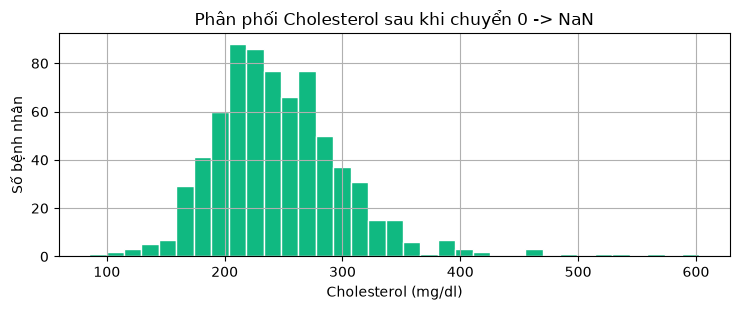

In [10]:
#chuỷn trestbps/chol == 0 thành NaN để xử lý outlier
df_clean.loc[df_clean["chol"] == 0, "chol"] = np.nan
df_clean.loc[df_clean["trestbps"] == 0, "trestbps"] = np.nan

print("Sau xử lý   -> chol==0:", (df_clean["chol"] == 0).sum(), "| trestbps==0:", (df_clean["trestbps"] == 0).sum())
print("Tổng NaN mới -> chol:", df_clean["chol"].isna().sum(), "| trestbps:", df_clean["trestbps"].isna().sum())
fig, ax = plt.subplots(figsize=(7.5, 3.2))
df_clean["chol"].dropna().hist(bins=35, ax=ax, color="#10b981", edgecolor="white")
ax.set_title("Phân phối Cholesterol sau khi chuyển 0 -> NaN")
ax.set_xlabel("Cholesterol (mg/dl)")
ax.set_ylabel("Số bệnh nhân")
plt.tight_layout()
plt.show()



In [11]:
#drop 2 cot ca và thal vì quá nhiều missing
df_clean = df_clean.drop(columns=["ca", "thal"])
print("Đã bỏ 'ca' và 'thal'. Các cột hiện tại:", list(df_clean.columns))

Đã bỏ 'ca' và 'thal'. Các cột hiện tại: ['age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'num']


In [12]:
print("Số dòng còn lại:", len(df_clean))
print("hiển thị các cột	hiện tại:", list(df_clean.columns))

Số dòng còn lại: 918
hiển thị các cột	hiện tại: ['age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'num']


In [13]:
#Tạo nhãn mục tiêu nhị phân (target) từ num
df_clean["target"] = (df_clean["num"] > 0).astype(int)
df_clean = df_clean.drop(columns=["num"])

print("Phân phối nhãn target:")
print(df_clean["target"].value_counts().rename({0: "0 - Khỏe", 1: "1 - Có bệnh"}))

Phân phối nhãn target:
target
1 - Có bệnh    508
0 - Khỏe       410
Name: count, dtype: int64


Chuẩn hóa giá trị các biến phân loại cho khớp 100% với Form Web

Việc làm: Chuyển sex (Male/Female 
→
→ "1"/"0"), fbs & exang (True/False 
→
→ "1"/"0"), và thay dấu cách/gạch ngang ở cp, restecg, slope thành dấu gạch dưới (_) để sau này API truyền thẳng giá trị từ form vào Pipeline không cần biến đổi rườm rà.

In [14]:
df_clean["sex"] = (df_clean["sex"] == "Male").astype(int).astype(str)
for c in ("fbs", "exang"):
    df_clean[c] = df_clean[c].map({True: "1", False: "0", "True": "1", "False": "0"})

df_clean["cp"] = df_clean["cp"].str.replace(" ", "_").str.replace("-", "_")
df_clean["restecg"] = df_clean["restecg"].str.replace(" ", "_").str.replace("-", "_")
df_clean["slope"] = df_clean["slope"].str.replace(" ", "_")

for col in ["sex", "fbs", "exang", "cp", "restecg", "slope"]:
    print(f"{col:8s} ->", df_clean[col].unique().tolist())

sex      -> ['1', '0']
fbs      -> ['1', '0', nan]
exang    -> ['0', '1', nan]
cp       -> ['typical_angina', 'asymptomatic', 'non_anginal', 'atypical_angina']
restecg  -> ['lv_hypertrophy', 'normal', 'st_t_abnormality', nan]
slope    -> ['downsloping', 'flat', 'upsloping', nan]


Chốt danh sách 11 đặc trưng (FEATURES) & kiểm tra tổng thể dữ liệu sạch

Việc làm: Khóa danh sách NUM_COLS (5 biến số) và CAT_COLS (6 biến phân loại) làm chuẩn đầu vào, thống kê lại số lượng NaN còn lại (những ô NaN này sẽ do Pipeline xử lý sau khi chia train/test).

In [15]:
NUM_COLS = ["age", "trestbps", "chol", "thalch", "oldpeak"]
CAT_COLS = ["sex", "fbs", "exang", "cp", "restecg", "slope"]
FEATURES = NUM_COLS + CAT_COLS

print(f"Kích thước bảng sạch: {df_clean.shape}")
print("\nSố giá trị NaN còn lại (sẽ được Imputer trong Pipeline điền sau khi split):")
print(df_clean[FEATURES].isna().sum())
display(df_clean[FEATURES + ["target"]].head(5))

Kích thước bảng sạch: (918, 13)

Số giá trị NaN còn lại (sẽ được Imputer trong Pipeline điền sau khi split):
age           0
trestbps     60
chol        201
thalch       55
oldpeak      62
sex           0
fbs          90
exang        55
cp            0
restecg       2
slope       307
dtype: int64


,age,trestbps,chol,thalch,oldpeak,sex,fbs,exang,cp,restecg,slope,target
0,63,145.0,233.0,150.0,2.3,1,1,0,typical_angina,lv_hypertrophy,downsloping,0
1,67,160.0,286.0,108.0,1.5,1,0,1,asymptomatic,lv_hypertrophy,flat,1
2,67,120.0,229.0,129.0,2.6,1,0,1,asymptomatic,lv_hypertrophy,flat,1
3,37,130.0,250.0,187.0,3.5,1,0,0,non_anginal,normal,downsloping,0
4,41,130.0,204.0,172.0,1.4,0,0,0,atypical_angina,lv_hypertrophy,upsloping,0


Vẽ Ma trận Tương quan (Correlation) của 5 biến số & target sau làm sạch

Việc làm: Kiểm tra xem sau khi bỏ các giá trị 0 vô lý ở chol và trestbps, mối quan hệ giữa các chỉ số số học và bệnh tim (target) trông như thế nào.

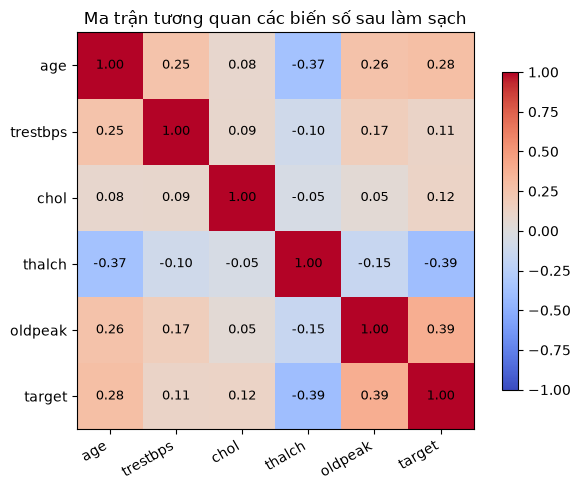

In [16]:
corr = df_clean[NUM_COLS + ["target"]].corr()

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=30, ha="right")
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", color="black", fontsize=9)
ax.set_title("Ma trận tương quan các biến số sau làm sạch")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

So sánh 3 mô hình trên Cross-Validation (Repeated 5-Fold × 2)

Tập Train: 734 mẫu (Tỉ lệ bệnh: 55.31%)
Tập Test:  184 mẫu (Tỉ lệ bệnh: 55.43%)


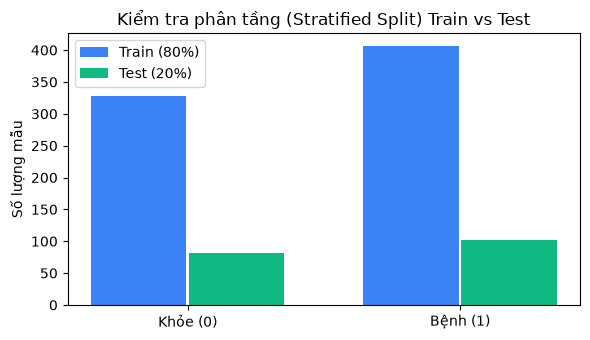

In [17]:
from sklearn.model_selection import train_test_split

X = df_clean[FEATURES]
y = df_clean["target"]
groups = df_clean["dataset"]

X_train, X_test, y_train, y_test, g_train, g_test = train_test_split(
    X, y, groups, test_size=0.2, stratify=y, random_state=42
)

print(f"Tập Train: {len(X_train)} mẫu (Tỉ lệ bệnh: {y_train.mean()*100:.2f}%)")
print(f"Tập Test:  {len(X_test)} mẫu (Tỉ lệ bệnh: {y_test.mean()*100:.2f}%)")

fig, ax = plt.subplots(figsize=(6, 3.5))
train_counts = [(y_train == 0).sum(), (y_train == 1).sum()]
test_counts  = [(y_test == 0).sum(),  (y_test == 1).sum()]
x_pos = np.arange(2)
ax.bar(x_pos - 0.18, train_counts, width=0.35, label="Train (80%)", color="#3b82f6")
ax.bar(x_pos + 0.18, test_counts,  width=0.35, label="Test (20%)",  color="#10b981")
ax.set_xticks(x_pos)
ax.set_xticklabels(["Khỏe (0)", "Bệnh (1)"])
ax.set_ylabel("Số lượng mẫu")
ax.set_title("Kiểm tra phân tầng (Stratified Split) Train vs Test")
ax.legend()
plt.tight_layout()
plt.show()

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier

def make_pipeline(model):
    preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), NUM_COLS),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), CAT_COLS),
    ])
    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model),
    ])

scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

candidates = {
    "LogisticRegression": lambda: make_pipeline(
        LogisticRegression(C=0.3, class_weight="balanced", max_iter=2000, random_state=42)
    ),
    "RandomForest": lambda: make_pipeline(
        RandomForestClassifier(
            n_estimators=500, min_samples_leaf=3,
            class_weight="balanced_subsample", random_state=42, n_jobs=-1
        )
    ),
    "HistGradientBoosting": lambda: make_pipeline(
        HistGradientBoostingClassifier(
            max_depth=3, learning_rate=0.05, max_iter=200,
            class_weight="balanced", random_state=42
        )
    ),
    "XGBoost": lambda: make_pipeline(
        XGBClassifier(
            max_depth=3, learning_rate=0.05, n_estimators=200,
            subsample=0.8, colsample_bytree=0.8,
            scale_pos_weight=scale_pos, eval_metric="logloss", random_state=42
        )
    ),
}

print("Đã định nghĩa Pipeline cho 4 ứng viên:", list(candidates.keys()))

Đã định nghĩa Pipeline cho 4 ứng viên: ['LogisticRegression', 'RandomForest', 'HistGradientBoosting', 'XGBoost']


,ROC-AUC,PR-AUC,Spec@Recall90,Threshold
LogisticRegression,0.8797,0.8788,0.7134,0.3696
HistGradientBoosting,0.8723,0.8544,0.6860,0.3396
RandomForest,0.8738,0.8663,0.6829,0.3975
XGBoost,0.8696,0.8534,0.6799,0.3432


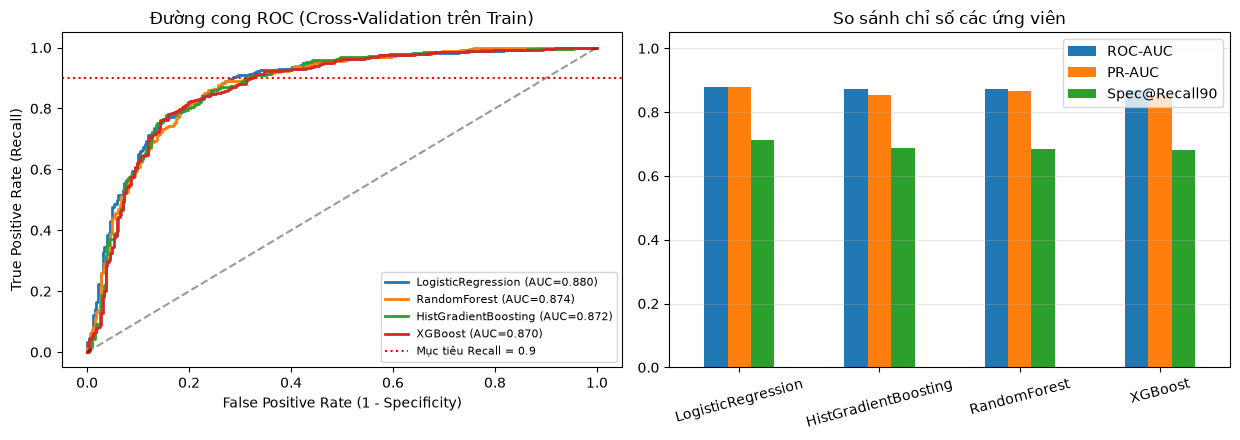

=> Mô hình thắng cuộc trên CV: LogisticRegression


In [19]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)
TARGET_RECALL = 0.90

def pick_threshold(y_true, probs, target_recall=TARGET_RECALL):
    fpr, tpr, thr = roc_curve(y_true, probs)
    idx = np.where(tpr >= target_recall)[0][0]
    return float(thr[idx]), float(tpr[idx]), float(1 - fpr[idx])

cv_results = {}
oof_preds = {}

for name, make_fn in candidates.items():
    oof = np.zeros(len(y_train))
    counts = np.zeros(len(y_train))
    for tr_idx, va_idx in cv.split(X_train, y_train):
        m = make_fn().fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        oof[va_idx] += m.predict_proba(X_train.iloc[va_idx])[:, 1]
        counts[va_idx] += 1
    oof /= counts
    oof_preds[name] = oof

    thr, rec, spec = pick_threshold(y_train, oof)
    cv_results[name] = {
        "ROC-AUC": roc_auc_score(y_train, oof),
        "PR-AUC": average_precision_score(y_train, oof),
        "Spec@Recall90": spec,
        "Threshold": thr,
    }

df_board = pd.DataFrame(cv_results).T.sort_values("Spec@Recall90", ascending=False)
display(df_board.round(4))

# Vẽ biểu đồ trực quan so sánh 3 mô hình
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))

for name, oof in oof_preds.items():
    fpr, tpr, _ = roc_curve(y_train, oof)
    axes[0].plot(fpr, tpr, linewidth=2, label=f"{name} (AUC={cv_results[name]['ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].axhline(TARGET_RECALL, color="red", linestyle=":", label=f"Mục tiêu Recall = {TARGET_RECALL}")
axes[0].set_title("Đường cong ROC (Cross-Validation trên Train)")
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(fontsize=8)

df_board[["ROC-AUC", "PR-AUC", "Spec@Recall90"]].plot(kind="bar", ax=axes[1], rot=15)
axes[1].set_title("So sánh chỉ số các ứng viên")
axes[1].set_ylim(0, 1.05)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

best_name = df_board.index[0]
print(f"=> Mô hình thắng cuộc trên CV: {best_name}")

Hiệu chỉnh xác suất (Calibration) & Vẽ biểu đồ chọn ngưỡng cắt (Threshold Tuning)

Brier Score (thấp hơn = xác suất chuẩn hơn): Trước Calib=0.1384 | Sau Calib=0.1373
Ngưỡng tối ưu đạt Recall >= 0.90: threshold = 0.437 -> Recall=0.901, Specificity=0.710


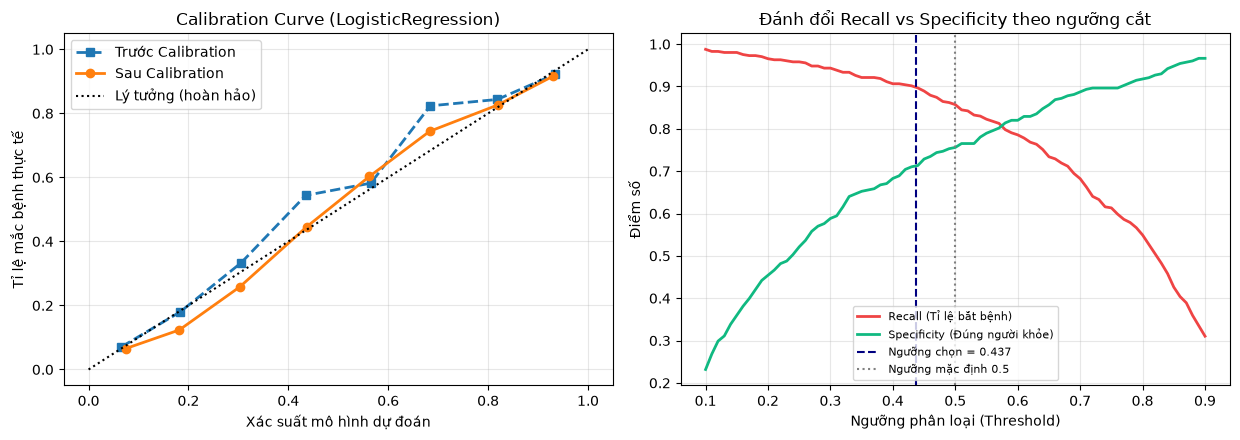

In [20]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import brier_score_loss

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Lấy mô hình thắng cuộc trên CV (LogisticRegression)
raw_model = candidates[best_name]()
cal_model = CalibratedClassifierCV(candidates[best_name](), method="sigmoid", cv=5)

oof_raw = cross_val_predict(raw_model, X_train, y_train, cv=skf, method="predict_proba")[:, 1]
oof_cal = cross_val_predict(cal_model, X_train, y_train, cv=skf, method="predict_proba")[:, 1]

best_threshold, rec_oof, spec_oof = pick_threshold(y_train, oof_cal, target_recall=0.90)
print(f"Brier Score (thấp hơn = xác suất chuẩn hơn): Trước Calib={brier_score_loss(y_train, oof_raw):.4f} | Sau Calib={brier_score_loss(y_train, oof_cal):.4f}")
print(f"Ngưỡng tối ưu đạt Recall >= 0.90: threshold = {best_threshold:.3f} -> Recall={rec_oof:.3f}, Specificity={spec_oof:.3f}")

# Vẽ 2 biểu đồ trực quan
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))

# 1. Calibration Curve
for label, probs, style in [("Trước Calibration", oof_raw, "s--"), ("Sau Calibration", oof_cal, "o-")]:
    frac_pos, mean_pred = calibration_curve(y_train, probs, n_bins=8)
    axes[0].plot(mean_pred, frac_pos, style, linewidth=2, label=label)
axes[0].plot([0, 1], [0, 1], "k:", label="Lý tưởng (hoàn hảo)")
axes[0].set_title(f"Calibration Curve ({best_name})")
axes[0].set_xlabel("Xác suất mô hình dự đoán")
axes[0].set_ylabel("Tỉ lệ mắc bệnh thực tế")
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2. Biểu đồ đánh đổi Recall vs Specificity theo ngưỡng
thrs = np.linspace(0.1, 0.9, 81)
recs = [((oof_cal >= t) & (y_train == 1)).sum() / (y_train == 1).sum() for t in thrs]
specs = [((oof_cal < t) & (y_train == 0)).sum() / (y_train == 0).sum() for t in thrs]

axes[1].plot(thrs, recs, label="Recall (Tỉ lệ bắt bệnh)", color="#ef4444", linewidth=2)
axes[1].plot(thrs, specs, label="Specificity (Đúng người khỏe)", color="#10b981", linewidth=2)
axes[1].axvline(best_threshold, color="navy", linestyle="--", label=f"Ngưỡng chọn = {best_threshold:.3f}")
axes[1].axvline(0.5, color="gray", linestyle=":", label="Ngưỡng mặc định 0.5")
axes[1].set_title("Đánh đổi Recall vs Specificity theo ngưỡng cắt")
axes[1].set_xlabel("Ngưỡng phân loại (Threshold)")
axes[1].set_ylabel("Điểm số")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Huấn luyện mô hình v2 trên tập Train & Đánh giá trên tập Test giữ riêng (Hold-out Test)

=== KẾT QUẢ TẬP TEST ĐỘC LẬP (n=184, threshold=0.437) ===
Recall (Tỉ lệ bắt bệnh):  0.912  (Chỉ sót 9/102 ca có bệnh)
Specificity (Đúng khỏe):  0.720
Precision:                0.802
Accuracy:                 0.826
ROC-AUC:                  0.912


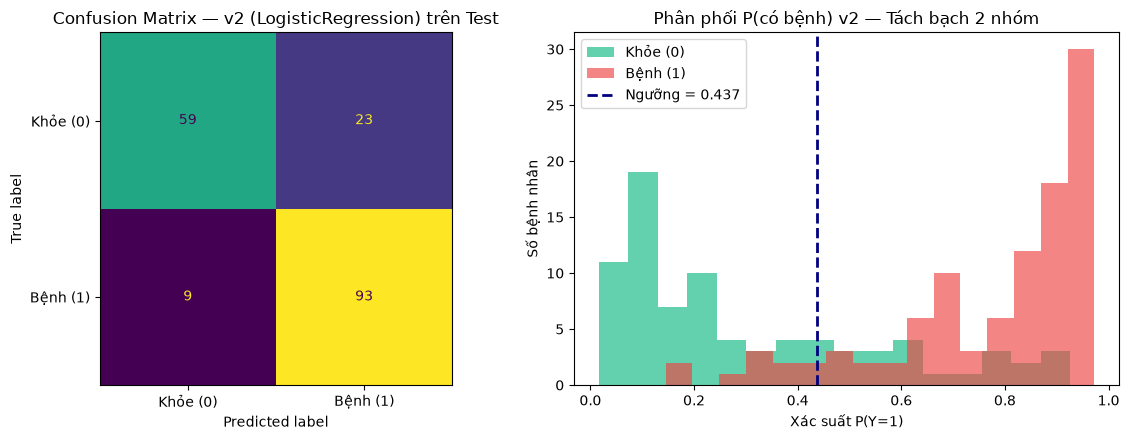

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

final_model = CalibratedClassifierCV(candidates[best_name](), method="sigmoid", cv=5)
final_model.fit(X_train, y_train)

p_test = final_model.predict_proba(X_test)[:, 1]
y_pred_test = (p_test >= best_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()
print(f"=== KẾT QUẢ TẬP TEST ĐỘC LẬP (n={len(y_test)}, threshold={best_threshold:.3f}) ===")
print(f"Recall (Tỉ lệ bắt bệnh):  {tp/(tp+fn):.3f}  (Chỉ sót {fn}/{tp+fn} ca có bệnh)")
print(f"Specificity (Đúng khỏe):  {tn/(tn+fp):.3f}")
print(f"Precision:                {tp/max(tp+fp,1):.3f}")
print(f"Accuracy:                 {(tp+tn)/len(y_test):.3f}")
print(f"ROC-AUC:                  {roc_auc_score(y_test, p_test):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_test), display_labels=["Khỏe (0)", "Bệnh (1)"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion Matrix — v2 ({best_name}) trên Test")

axes[1].hist(p_test[y_test == 0], bins=16, alpha=0.65, label="Khỏe (0)", color="#10b981")
axes[1].hist(p_test[y_test == 1], bins=16, alpha=0.65, label="Bệnh (1)", color="#ef4444")
axes[1].axvline(best_threshold, color="navy", linestyle="--", linewidth=2, label=f"Ngưỡng = {best_threshold:.3f}")
axes[1].set_title("Phân phối P(có bệnh) v2 — Tách bạch 2 nhóm")
axes[1].set_xlabel("Xác suất P(Y=1)")
axes[1].set_ylabel("Số bệnh nhân")
axes[1].legend()
plt.tight_layout()
plt.show()

 Kiểm tra tổng quát hóa giữa các bệnh viện (Leave-One-Source-Out) để chứng minh mô hình mới không hề học vẹt theo nguồn bệnh viện mà mang sang bệnh viện lạ vẫn bắt bệnh tốt.

,Số mẫu,Tỉ lệ bệnh thật,Recall,Specificity,ROC-AUC
Bệnh viện Test,,,,,
Cleveland,304,0.457,0.906,0.582,0.874
Hungary,292,0.363,0.906,0.753,0.895
Switzerland,123,0.935,0.826,0.625,0.749
VA Long Beach,199,0.744,0.858,0.471,0.751


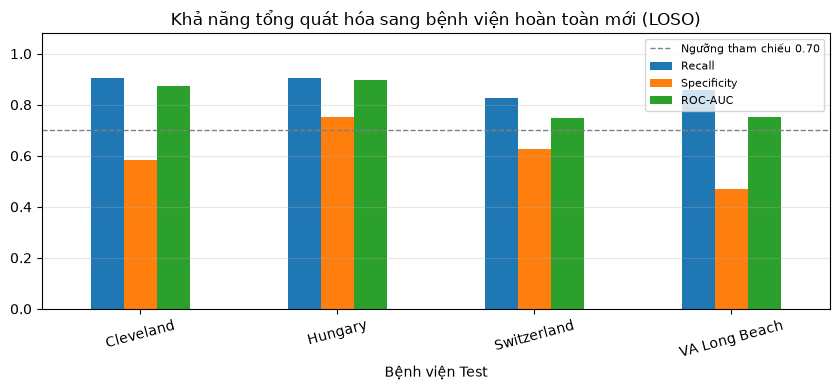

In [22]:
from sklearn.model_selection import LeaveOneGroupOut

loso_rows = []
for tr_i, va_i in LeaveOneGroupOut().split(X, y, groups):
    src = groups.iloc[va_i[0]]
    m = CalibratedClassifierCV(candidates[best_name](), method="sigmoid", cv=5)
    m.fit(X.iloc[tr_i], y.iloc[tr_i])
    p = m.predict_proba(X.iloc[va_i])[:, 1]
    pred = (p >= best_threshold).astype(int)
    tn_s, fp_s, fn_s, tp_s = confusion_matrix(y.iloc[va_i], pred).ravel()
    loso_rows.append({
        "Bệnh viện Test": src,
        "Số mẫu": len(va_i),
        "Tỉ lệ bệnh thật": y.iloc[va_i].mean(),
        "Recall": tp_s / max(tp_s + fn_s, 1),
        "Specificity": tn_s / max(tn_s + fp_s, 1),
        "ROC-AUC": roc_auc_score(y.iloc[va_i], p) if y.iloc[va_i].nunique() == 2 else np.nan,
    })

df_loso = pd.DataFrame(loso_rows).set_index("Bệnh viện Test")
display(df_loso.round(3))

ax = df_loso[["Recall", "Specificity", "ROC-AUC"]].plot(kind="bar", figsize=(8.5, 4), rot=15)
ax.axhline(0.70, color="gray", linestyle="--", linewidth=1, label="Ngưỡng tham chiếu 0.70")
ax.set_ylim(0, 1.08)
ax.set_title("Khả năng tổng quát hóa sang bệnh viện hoàn toàn mới (LOSO)")
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Giải thích mô hình — Những yếu tố nào quyết định nguy cơ tim mạch?

Mục đích: Lấy bộ hệ số (weights) của Logistic Regression bên trong final_model sau khi đã chuẩn hóa, vẽ biểu đồ thanh ngang:

Màu đỏ (hệ số dương): Chỉ số càng cao / có đặc điểm này 
→
→ càng dễ mắc bệnh.
Màu xanh (hệ số âm): Chỉ số càng cao / có đặc điểm này 
→
→ nguy cơ càng thấp.

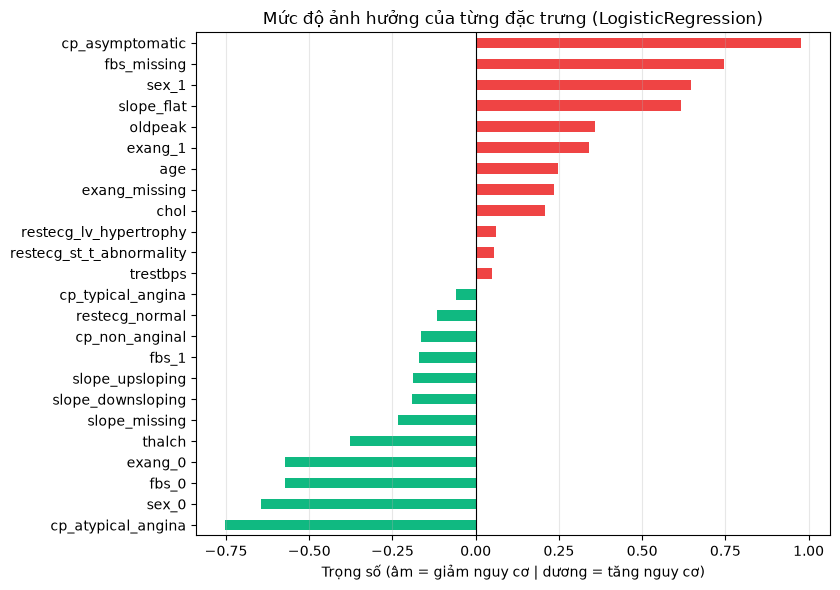

In [23]:
# Lấy trung bình hệ số từ 5 fold bên trong CalibratedClassifierCV
coefs = np.mean([cc.estimator.named_steps["classifier"].coef_[0] for cc in final_model.calibrated_classifiers_], axis=0)
feat_names = final_model.calibrated_classifiers_[0].estimator.named_steps["preprocessor"].get_feature_names_out()
feat_names = [n.replace("num__", "").replace("cat__", "") for n in feat_names]

imp = pd.Series(coefs, index=feat_names).sort_values()

fig, ax = plt.subplots(figsize=(8.5, 6))
colors = ["#10b981" if v < 0 else "#ef4444" for v in imp.values]
imp.plot(kind="barh", ax=ax, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(f"Mức độ ảnh hưởng của từng đặc trưng ({best_name})")
ax.set_xlabel("Trọng số (âm = giảm nguy cơ | dương = tăng nguy cơ)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Phát hiện từ Feature Importance & Khắc phục `*_missing` shortcut
Từ biểu đồ trọng số ở trên, ta phát hiện **`fbs_missing` (+0.74)** đứng thứ 2 về mức độ ảnh hưởng. Nguyên nhân là do bệnh viện *Switzerland* (tỉ lệ bệnh 93.5%) bị thiếu `fbs` rất nhiều, khiến Imputer điền `"missing"` vô tình tạo thành cờ nhận diện ngầm bệnh viện nguồn — trong khi trên form web thực tế người dùng luôn chọn `0` hoặc `1`.

**Cách xử lý:** Đổi `SimpleImputer` cho biến phân loại từ `constant ("missing")` sang `most_frequent` (điền giá trị phổ biến nhất của tập train), loại bỏ hoàn toàn các cột `*_missing`, sau đó chạy lại Calibration + Threshold Tuning và kiểm tra lại biểu đồ trọng số.

=== KẾT QUẢ SAU KHI BỎ *_missing (threshold=0.415) ===
Test Recall:      0.922 (sót 8/102 ca)
Test Specificity: 0.683
Test Accuracy:    0.815 | ROC-AUC: 0.891


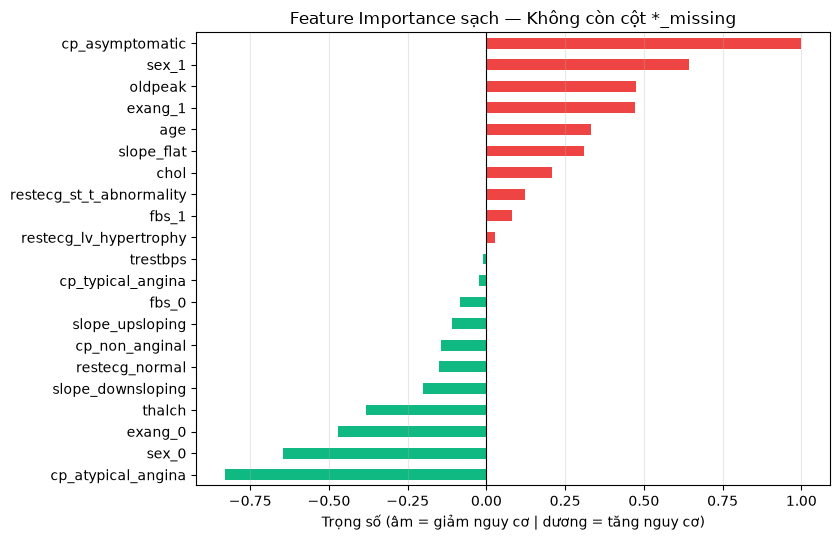

Đã xuất xưởng tại: e:\heart predict\models\v2
  -> Ca khỏe (Nữ 30t): P(bệnh) = 2.0% | Kết luận = AN TOÀN (0)
  -> Ca nguy cơ cao (Nam 65t): P(bệnh) = 98.2% | Kết luận = CÓ NGUY CƠ (1)


In [24]:
import hashlib, json, platform
from datetime import datetime, timezone
import sklearn

# 1. Định nghĩa lại Pipeline v2 sạch hoàn toàn (không còn *_missing)
def make_clean_pipeline(model):
    preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), NUM_COLS),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), CAT_COLS),
    ])
    return Pipeline([("preprocessor", preprocessor), ("classifier", model)])

base_clf = lambda: make_clean_pipeline(
    LogisticRegression(C=0.3, class_weight="balanced", max_iter=2000, random_state=42)
)

# 2. Calibration & chọn lại ngưỡng trên OOF của X_train
cal_clean = CalibratedClassifierCV(base_clf(), method="sigmoid", cv=5)
oof_clean = cross_val_predict(cal_clean, X_train, y_train, cv=skf, method="predict_proba")[:, 1]
thr_clean, rec_oof_c, spec_oof_c = pick_threshold(y_train, oof_clean, target_recall=0.90)

# 3. Fit trên X_train & đo trên X_test độc lập
cal_clean.fit(X_train, y_train)
p_test_c = cal_clean.predict_proba(X_test)[:, 1]
pred_test_c = (p_test_c >= thr_clean).astype(int)
tn_c, fp_c, fn_c, tp_c = confusion_matrix(y_test, pred_test_c).ravel()

print(f"=== KẾT QUẢ SAU KHI BỎ *_missing (threshold={thr_clean:.3f}) ===")
print(f"Test Recall:      {tp_c/(tp_c+fn_c):.3f} (sót {fn_c}/{tp_c+fn_c} ca)")
print(f"Test Specificity: {tn_c/(tn_c+fp_c):.3f}")
print(f"Test Accuracy:    {(tp_c+tn_c)/len(y_test):.3f} | ROC-AUC: {roc_auc_score(y_test, p_test_c):.3f}")

# 4. Vẽ lại Feature Importance để chứng minh không còn *_missing
coefs_c = np.mean([cc.estimator.named_steps["classifier"].coef_[0] for cc in cal_clean.calibrated_classifiers_], axis=0)
fnames_c = [n.replace("num__", "").replace("cat__", "")
            for n in cal_clean.calibrated_classifiers_[0].estimator.named_steps["preprocessor"].get_feature_names_out()]
imp_c = pd.Series(coefs_c, index=fnames_c).sort_values()

fig, ax = plt.subplots(figsize=(8.5, 5.5))
imp_c.plot(kind="barh", ax=ax, color=["#10b981" if v < 0 else "#ef4444" for v in imp_c.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Feature Importance sạch — Không còn cột *_missing")
ax.set_xlabel("Trọng số (âm = giảm nguy cơ | dương = tăng nguy cơ)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Xuất xưởng models/v2/ (fit trên toàn bộ dữ liệu)
OUT_DIR = ROOT / "models/v2"
OUT_DIR.mkdir(parents=True, exist_ok=True)
deploy_model = CalibratedClassifierCV(base_clf(), method="sigmoid", cv=5).fit(X, y)
joblib.dump(deploy_model, OUT_DIR / "pipeline.joblib")

model_card = {
    "version": "v2",
    "trained_at": datetime.now(timezone.utc).isoformat(),
    "model": "LogisticRegression",
    "data_sha256": hashlib.sha256((ROOT / "data/raw_data/heart_disease_uci.csv").read_bytes()).hexdigest(),
    "n_rows": int(len(df_clean)),
    "features": {"numeric": NUM_COLS, "categorical": CAT_COLS},
    "threshold": round(float(thr_clean), 4),
    "target_recall": 0.90,
    "risk_bands": {
        "low": round(float(thr_clean * 0.5), 4),
        "medium": round(float(thr_clean), 4),
        "high": round(float((thr_clean + 1.0) / 2.0), 4),
    },
    "test_metrics": {
        "n": int(len(y_test)),
        "recall": round(float(tp_c / (tp_c + fn_c)), 4),
        "specificity": round(float(tn_c / (tn_c + fp_c)), 4),
        "precision": round(float(tp_c / max(tp_c + fp_c, 1)), 4),
        "accuracy": round(float((tp_c + tn_c) / len(y_test)), 4),
        "roc_auc": round(float(roc_auc_score(y_test, p_test_c)), 4),
    },
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__},
}
(OUT_DIR / "model_card.json").write_text(json.dumps(model_card, ensure_ascii=False, indent=2), encoding="utf-8")
print("Đã xuất xưởng tại:", OUT_DIR)

# 6. Sanity test 2 ca mẫu
sanity = pd.DataFrame([
    {"age": 30, "trestbps": 115, "chol": 180, "thalch": 180, "oldpeak": 0.0,
     "sex": "0", "fbs": "0", "exang": "0", "cp": "non_anginal", "restecg": "normal", "slope": "upsloping"},
    {"age": 65, "trestbps": 160, "chol": 280, "thalch": 108, "oldpeak": 3.0,
     "sex": "1", "fbs": "1", "exang": "1", "cp": "asymptomatic", "restecg": "st_t_abnormality", "slope": "flat"},
])[FEATURES]
for label, p in zip(["Ca khỏe (Nữ 30t)", "Ca nguy cơ cao (Nam 65t)"], deploy_model.predict_proba(sanity)[:, 1]):
    print(f"  -> {label}: P(bệnh) = {p*100:.1f}% | Kết luận = {'CÓ NGUY CƠ (1)' if p >= thr_clean else 'AN TOÀN (0)'}")